<a href="https://colab.research.google.com/github/MominaShahzad100/Python-Git-Project/blob/main/AI_Lab_07.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.datasets import load_iris
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report,
    ConfusionMatrixDisplay
)

print("All libraries imported successfully!")

All libraries imported successfully!


In [3]:
# Load the Iris dataset
iris = load_iris()

# Create a Pandas DataFrame
df = pd.DataFrame(
    iris.data,
    columns=iris.feature_names
)

# Add the target species
df["species"] = pd.Categorical.from_codes(
    iris.target,
    iris.target_names
)

# Display the first five rows
print("First five rows of the dataset:")
display(df.head())

# Display dataset dimensions
print("Dataset shape:", df.shape)

First five rows of the dataset:


,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm),species
0,5.1,3.5,1.4,0.2,setosa
1,4.9,3.0,1.4,0.2,setosa
2,4.7,3.2,1.3,0.2,setosa
3,4.6,3.1,1.5,0.2,setosa
4,5.0,3.6,1.4,0.2,setosa


Dataset shape: (150, 5)


In [4]:
# Select input features
X = df[iris.feature_names]

# Select target variable
y = iris.target

print("Input features:")
display(X.head())

print("\nTarget species:")
print(iris.target_names)

print("\nNumber of input features:", X.shape[1])
print("Number of target samples:", len(y))

Input features:


,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm)
0,5.1,3.5,1.4,0.2
1,4.9,3.0,1.4,0.2
2,4.7,3.2,1.3,0.2
3,4.6,3.1,1.5,0.2
4,5.0,3.6,1.4,0.2



Target species:
['setosa' 'versicolor' 'virginica']

Number of input features: 4
Number of target samples: 150


In [5]:
print("Dataset information:")
df.info()

print("\nStatistical summary:")
display(df.describe())

Dataset information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 150 entries, 0 to 149
Data columns (total 5 columns):
 #   Column             Non-Null Count  Dtype   
---  ------             --------------  -----   
 0   sepal length (cm)  150 non-null    float64 
 1   sepal width (cm)   150 non-null    float64 
 2   petal length (cm)  150 non-null    float64 
 3   petal width (cm)   150 non-null    float64 
 4   species            150 non-null    category
dtypes: category(1), float64(4)
memory usage: 5.1 KB

Statistical summary:


,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm)
count,150.000000,150.000000,150.000000,150.000000
mean,5.843333,3.057333,3.758000,1.199333
std,0.828066,0.435866,1.765298,0.762238
min,4.300000,2.000000,1.000000,0.100000
25%,5.100000,2.800000,1.600000,0.300000
50%,5.800000,3.000000,4.350000,1.300000
75%,6.400000,3.300000,5.100000,1.800000
max,7.900000,4.400000,6.900000,2.500000


In [6]:
print("Missing values in each column:")
print(df.isnull().sum())

print("\nTotal missing values:", df.isnull().sum().sum())

print("\nNumber of duplicate rows:", df.duplicated().sum())

Missing values in each column:
sepal length (cm)    0
sepal width (cm)     0
petal length (cm)    0
petal width (cm)     0
species              0
dtype: int64

Total missing values: 0

Number of duplicate rows: 1


Number of samples in each species:
species
setosa        50
versicolor    50
virginica     50
Name: count, dtype: int64


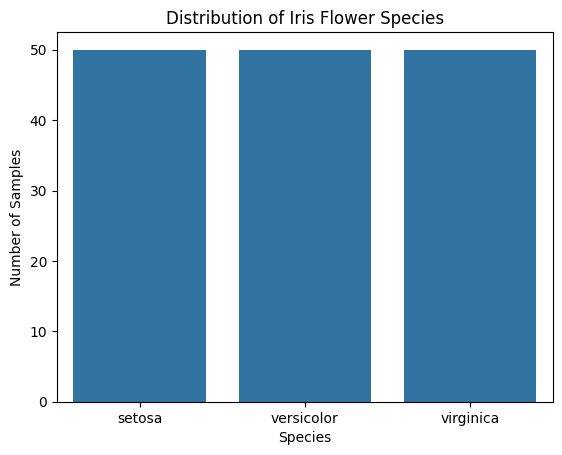

In [7]:
print("Number of samples in each species:")
print(df["species"].value_counts())

sns.countplot(data=df, x="species")
plt.title("Distribution of Iris Flower Species")
plt.xlabel("Species")
plt.ylabel("Number of Samples")
plt.show()

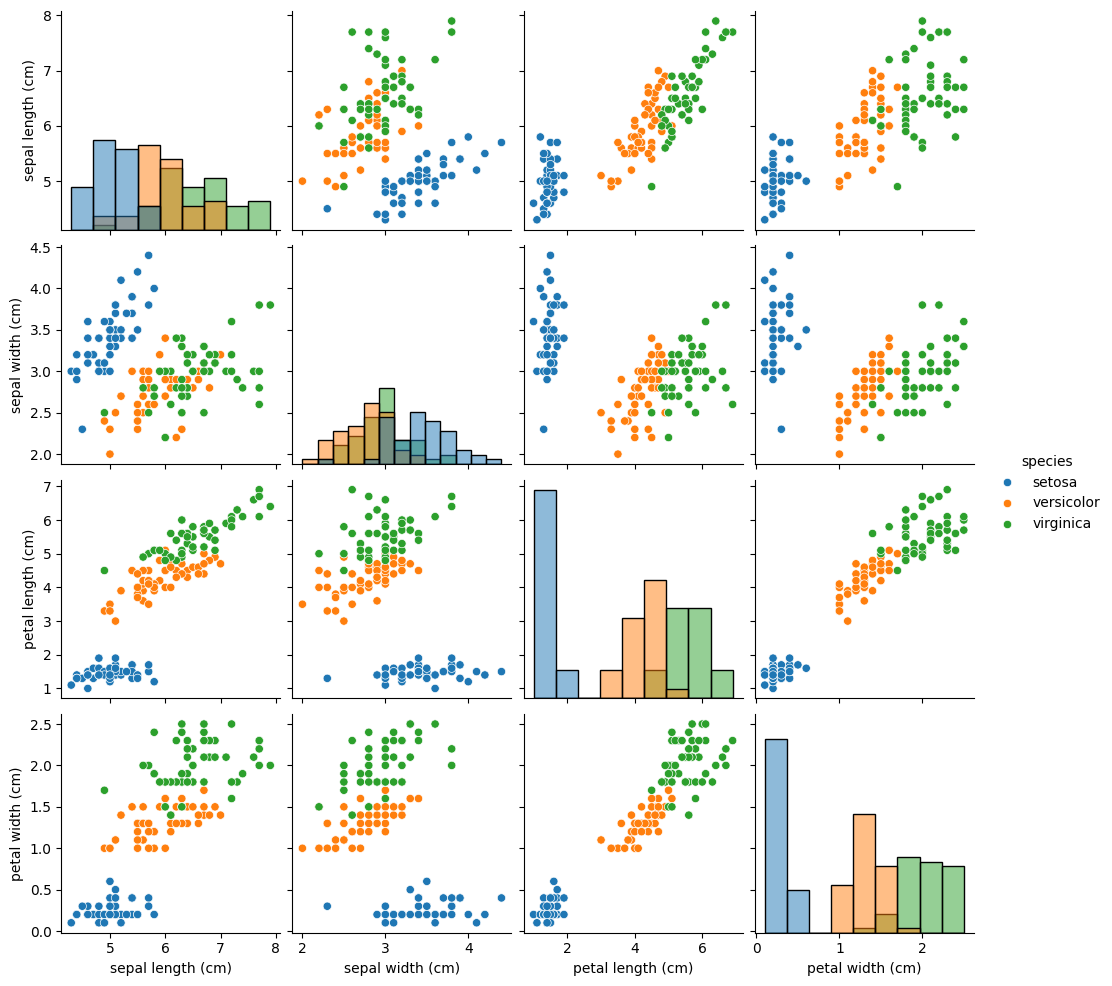

In [8]:
sns.pairplot(df, hue="species", diag_kind="hist")
plt.show()

In [9]:
# Check data types
print(df.dtypes)

# Check missing values in input features
print("\nMissing input values:", X.isnull().sum().sum())

# Check target class distribution
print("\nTarget distribution:")
print(pd.Series(y).value_counts().sort_index())

sepal length (cm)     float64
sepal width (cm)      float64
petal length (cm)     float64
petal width (cm)      float64
species              category
dtype: object

Missing input values: 0

Target distribution:
0    50
1    50
2    50
Name: count, dtype: int64


In [10]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training samples:", len(X_train))
print("Testing samples:", len(X_test))

print("\nTraining class distribution:")
print(pd.Series(y_train).value_counts().sort_index())

print("\nTesting class distribution:")
print(pd.Series(y_test).value_counts().sort_index())

Training samples: 120
Testing samples: 30

Training class distribution:
0    40
1    40
2    40
Name: count, dtype: int64

Testing class distribution:
0    10
1    10
2    10
Name: count, dtype: int64


In [11]:
# Create the Decision Tree model
model = DecisionTreeClassifier(
    criterion="gini",
    max_depth=4,
    random_state=42
)

# Train the model
model.fit(X_train, y_train)

print("Decision Tree model trained successfully!")

Decision Tree model trained successfully!


In [12]:
# Generate predictions
y_pred = model.predict(X_test)

# Display actual and predicted species
results = pd.DataFrame({
    "Actual Species": iris.target_names[y_test],
    "Predicted Species": iris.target_names[y_pred]
})

display(results)

print("Predictions generated successfully!")

,Actual Species,Predicted Species
0,setosa,setosa
1,virginica,virginica
2,versicolor,versicolor
3,versicolor,versicolor
4,setosa,setosa
5,versicolor,versicolor
6,setosa,setosa
7,setosa,setosa
8,virginica,virginica
9,versicolor,versicolor


Predictions generated successfully!


In [13]:
# Calculate evaluation metrics
accuracy = accuracy_score(y_test, y_pred)

precision = precision_score(
    y_test, y_pred, average="macro", zero_division=0
)

recall = recall_score(
    y_test, y_pred, average="macro", zero_division=0
)

f1 = f1_score(
    y_test, y_pred, average="macro", zero_division=0
)

print(f"Accuracy:  {accuracy:.4f}")
print(f"Precision: {precision:.4f}")
print(f"Recall:    {recall:.4f}")
print(f"F1-score:  {f1:.4f}")

Accuracy:  0.9333
Precision: 0.9333
Recall:    0.9333
F1-score:  0.9333


In [14]:
print(
    classification_report(
        y_test,
        y_pred,
        labels=[0, 1, 2],
        target_names=iris.target_names,
        zero_division=0
    )
)

              precision    recall  f1-score   support

      setosa       1.00      1.00      1.00        10
  versicolor       0.90      0.90      0.90        10
   virginica       0.90      0.90      0.90        10

    accuracy                           0.93        30
   macro avg       0.93      0.93      0.93        30
weighted avg       0.93      0.93      0.93        30



Confusion Matrix:
[[10  0  0]
 [ 0  9  1]
 [ 0  1  9]]


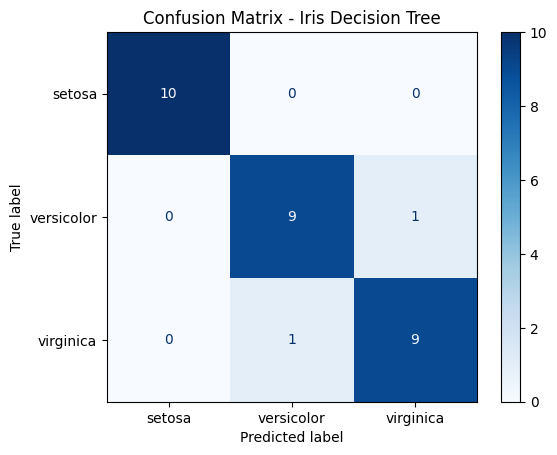

In [15]:
# Calculate confusion matrix
cm = confusion_matrix(y_test, y_pred, labels=[0, 1, 2])

print("Confusion Matrix:")
print(cm)

# Visualize the confusion matrix
disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=iris.target_names
)

disp.plot(cmap="Blues", values_format="d")
plt.title("Confusion Matrix - Iris Decision Tree")
plt.show()

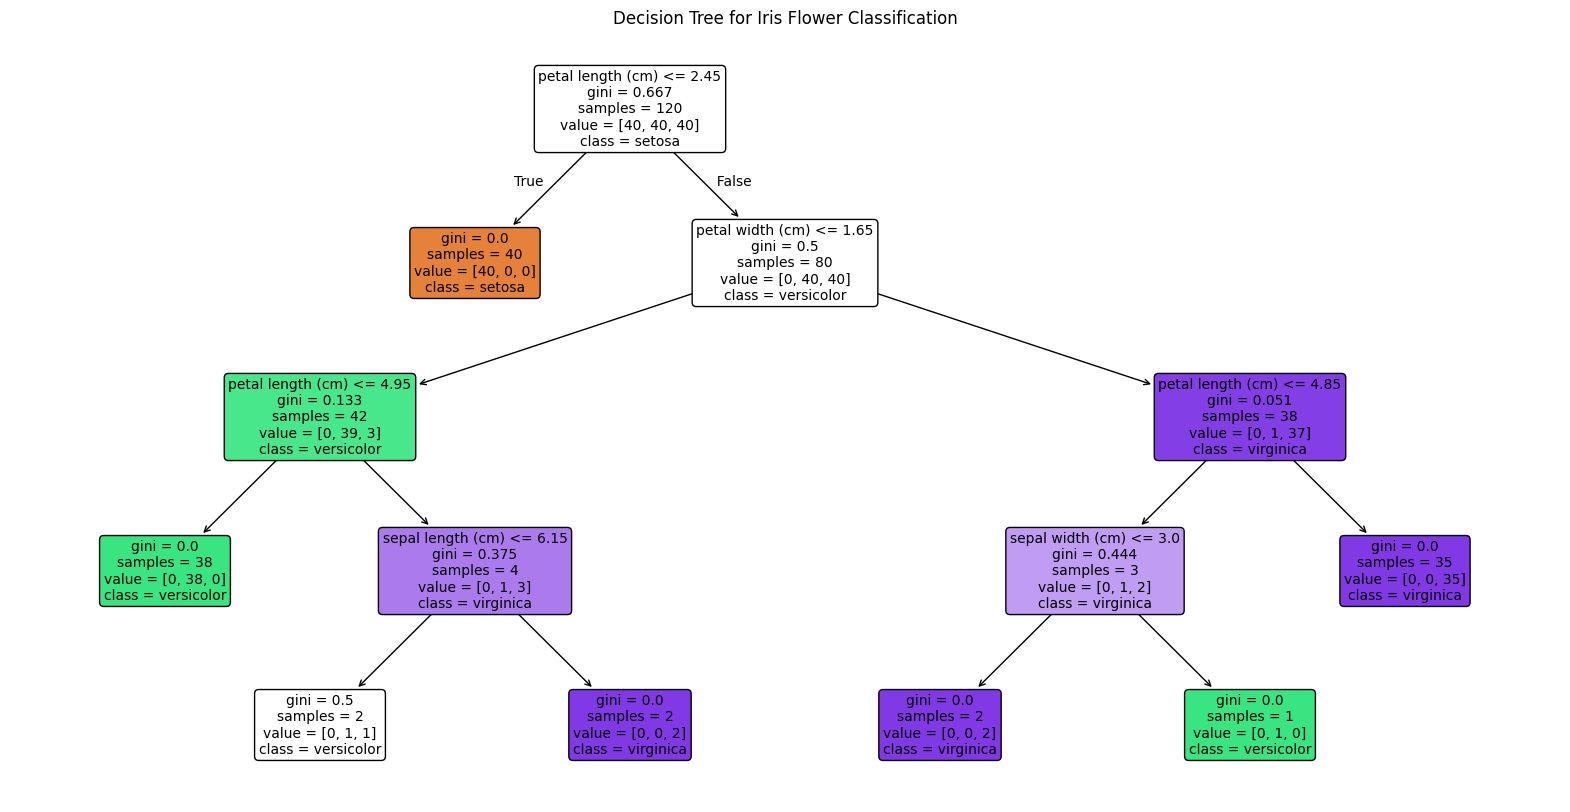

In [16]:
plt.figure(figsize=(20, 10))

plot_tree(
    model,
    feature_names=iris.feature_names,
    class_names=iris.target_names,
    filled=True,
    rounded=True,
    fontsize=10
)

plt.title("Decision Tree for Iris Flower Classification")
plt.show()

In [17]:
# Find incorrectly classified samples
misclassified = results[
    results["Actual Species"] != results["Predicted Species"]
]

print("Total test samples:", len(y_test))
print("Correct predictions:", (y_test == y_pred).sum())
print("Incorrect predictions:", (y_test != y_pred).sum())

print("\nMisclassified samples:")
if misclassified.empty:
    print("No misclassified samples.")
else:
    display(misclassified)

Total test samples: 30
Correct predictions: 28
Incorrect predictions: 2

Misclassified samples:


,Actual Species,Predicted Species
23,virginica,versicolor
25,versicolor,virginica


In [18]:
print("=" * 50)
print("IRIS FLOWER CLASSIFICATION - FINAL SUMMARY")
print("=" * 50)

print("Dataset: Iris")
print("Total samples:", len(df))
print("Input features:", X.shape[1])
print("Target classes:", ", ".join(iris.target_names))
print("Training samples:", len(X_train))
print("Testing samples:", len(X_test))

print(f"\nAccuracy:  {accuracy * 100:.2f}%")
print(f"Precision: {precision * 100:.2f}%")
print(f"Recall:    {recall * 100:.2f}%")
print(f"F1-score:  {f1 * 100:.2f}%")

print("\nCorrect predictions:", (y_test == y_pred).sum())
print("Incorrect predictions:", (y_test != y_pred).sum())

print("\nExperiment completed successfully.")

IRIS FLOWER CLASSIFICATION - FINAL SUMMARY
Dataset: Iris
Total samples: 150
Input features: 4
Target classes: setosa, versicolor, virginica
Training samples: 120
Testing samples: 30

Accuracy:  93.33%
Precision: 93.33%
Recall:    93.33%
F1-score:  93.33%

Correct predictions: 28
Incorrect predictions: 2

Experiment completed successfully.


In [19]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.datasets import (
    load_breast_cancer,
    load_wine,
    load_diabetes
)

from sklearn.model_selection import train_test_split

from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier, GradientBoostingRegressor

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report,
    ConfusionMatrixDisplay,
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

print("All libraries imported successfully!")

All libraries imported successfully!


In [20]:
# Load dataset
cancer = load_breast_cancer()

# Create DataFrame
cancer_df = pd.DataFrame(
    cancer.data,
    columns=cancer.feature_names
)

cancer_df["target"] = cancer.target

print("First five rows:")
display(cancer_df.head())

print("\nDataset shape:", cancer_df.shape)

print("\nTarget classes:")
print(dict(enumerate(cancer.target_names)))

print("\nClass distribution:")
print(cancer_df["target"].value_counts().sort_index())

First five rows:


,mean radius,mean texture,mean perimeter,mean area,mean smoothness,mean compactness,mean concavity,mean concave points,mean symmetry,mean fractal dimension,...,worst texture,worst perimeter,worst area,worst smoothness,worst compactness,worst concavity,worst concave points,worst symmetry,worst fractal dimension,target
0,17.99,10.38,122.80,1001.0,0.11840,0.27760,0.3001,0.14710,0.2419,0.07871,...,17.33,184.60,2019.0,0.1622,0.6656,0.7119,0.2654,0.4601,0.11890,0
1,20.57,17.77,132.90,1326.0,0.08474,0.07864,0.0869,0.07017,0.1812,0.05667,...,23.41,158.80,1956.0,0.1238,0.1866,0.2416,0.1860,0.2750,0.08902,0
2,19.69,21.25,130.00,1203.0,0.10960,0.15990,0.1974,0.12790,0.2069,0.05999,...,25.53,152.50,1709.0,0.1444,0.4245,0.4504,0.2430,0.3613,0.08758,0
3,11.42,20.38,77.58,386.1,0.14250,0.28390,0.2414,0.10520,0.2597,0.09744,...,26.50,98.87,567.7,0.2098,0.8663,0.6869,0.2575,0.6638,0.17300,0
4,20.29,14.34,135.10,1297.0,0.10030,0.13280,0.1980,0.10430,0.1809,0.05883,...,16.67,152.20,1575.0,0.1374,0.2050,0.4000,0.1625,0.2364,0.07678,0



Dataset shape: (569, 31)

Target classes:
{0: np.str_('malignant'), 1: np.str_('benign')}

Class distribution:
target
0    212
1    357
Name: count, dtype: int64


In [21]:
print("Dataset information:")
cancer_df.info()

print("\nStatistical summary:")
display(cancer_df.describe())

print("\nMissing values:", cancer_df.isnull().sum().sum())

print("Duplicate rows:", cancer_df.duplicated().sum())

print("\nTarget class names:", cancer.target_names)

Dataset information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 569 entries, 0 to 568
Data columns (total 31 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   mean radius              569 non-null    float64
 1   mean texture             569 non-null    float64
 2   mean perimeter           569 non-null    float64
 3   mean area                569 non-null    float64
 4   mean smoothness          569 non-null    float64
 5   mean compactness         569 non-null    float64
 6   mean concavity           569 non-null    float64
 7   mean concave points      569 non-null    float64
 8   mean symmetry            569 non-null    float64
 9   mean fractal dimension   569 non-null    float64
 10  radius error             569 non-null    float64
 11  texture error            569 non-null    float64
 12  perimeter error          569 non-null    float64
 13  area error               569 non-null    float64
 14  smoot

,mean radius,mean texture,mean perimeter,mean area,mean smoothness,mean compactness,mean concavity,mean concave points,mean symmetry,mean fractal dimension,...,worst texture,worst perimeter,worst area,worst smoothness,worst compactness,worst concavity,worst concave points,worst symmetry,worst fractal dimension,target
count,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,...,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000
mean,14.127292,19.289649,91.969033,654.889104,0.096360,0.104341,0.088799,0.048919,0.181162,0.062798,...,25.677223,107.261213,880.583128,0.132369,0.254265,0.272188,0.114606,0.290076,0.083946,0.627417
std,3.524049,4.301036,24.298981,351.914129,0.014064,0.052813,0.079720,0.038803,0.027414,0.007060,...,6.146258,33.602542,569.356993,0.022832,0.157336,0.208624,0.065732,0.061867,0.018061,0.483918
min,6.981000,9.710000,43.790000,143.500000,0.052630,0.019380,0.000000,0.000000,0.106000,0.049960,...,12.020000,50.410000,185.200000,0.071170,0.027290,0.000000,0.000000,0.156500,0.055040,0.000000
25%,11.700000,16.170000,75.170000,420.300000,0.086370,0.064920,0.029560,0.020310,0.161900,0.057700,...,21.080000,84.110000,515.300000,0.116600,0.147200,0.114500,0.064930,0.250400,0.071460,0.000000
50%,13.370000,18.840000,86.240000,551.100000,0.095870,0.092630,0.061540,0.033500,0.179200,0.061540,...,25.410000,97.660000,686.500000,0.131300,0.211900,0.226700,0.099930,0.282200,0.080040,1.000000
75%,15.780000,21.800000,104.100000,782.700000,0.105300,0.130400,0.130700,0.074000,0.195700,0.066120,...,29.720000,125.400000,1084.000000,0.146000,0.339100,0.382900,0.161400,0.317900,0.092080,1.000000
max,28.110000,39.280000,188.500000,2501.000000,0.163400,0.345400,0.426800,0.201200,0.304000,0.097440,...,49.540000,251.200000,4254.000000,0.222600,1.058000,1.252000,0.291000,0.663800,0.207500,1.000000



Missing values: 0
Duplicate rows: 0

Target class names: ['malignant' 'benign']


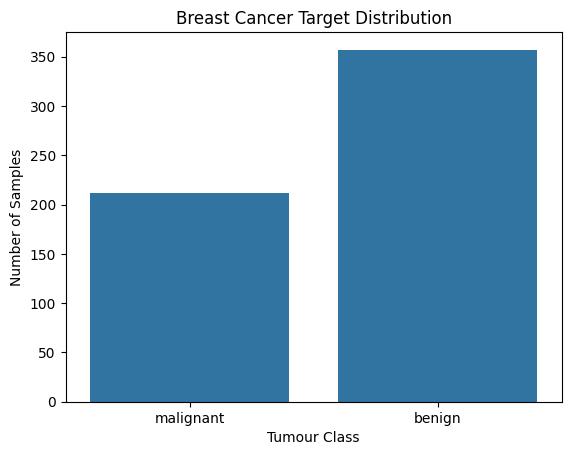

In [22]:
sns.countplot(
    x=pd.Series(cancer.target).map(
        {i: name for i, name in enumerate(cancer.target_names)}
    )
)

plt.title("Breast Cancer Target Distribution")
plt.xlabel("Tumour Class")
plt.ylabel("Number of Samples")
plt.show()

In [23]:
# Input features and target
X_cancer = cancer.data
y_cancer = cancer.target

print("Number of input features:", X_cancer.shape[1])
print("Number of samples:", X_cancer.shape[0])

# 80% training, 20% testing
Xc_train, Xc_test, yc_train, yc_test = train_test_split(
    X_cancer,
    y_cancer,
    test_size=0.20,
    random_state=42,
    stratify=y_cancer
)

print("\nTraining samples:", len(Xc_train))
print("Testing samples:", len(Xc_test))

Number of input features: 30
Number of samples: 569

Training samples: 455
Testing samples: 114


In [24]:
# Create model
dt_model = DecisionTreeClassifier(
    criterion="gini",
    max_depth=5,
    random_state=42
)

# Train model
dt_model.fit(Xc_train, yc_train)

# Generate predictions
yc_pred = dt_model.predict(Xc_test)

print("Decision Tree trained successfully!")
print("\nFirst 10 actual labels:", yc_test[:10])
print("First 10 predicted labels:", yc_pred[:10])

Decision Tree trained successfully!

First 10 actual labels: [0 1 0 1 0 1 1 0 0 0]
First 10 predicted labels: [0 1 0 1 0 1 1 0 0 0]


In [25]:
# Calculate classification metrics
cancer_accuracy = accuracy_score(yc_test, yc_pred)

cancer_precision = precision_score(
    yc_test, yc_pred, average="macro", zero_division=0
)

cancer_recall = recall_score(
    yc_test, yc_pred, average="macro", zero_division=0
)

cancer_f1 = f1_score(
    yc_test, yc_pred, average="macro", zero_division=0
)

print(f"Accuracy:  {cancer_accuracy:.4f}")
print(f"Precision: {cancer_precision:.4f}")
print(f"Recall:    {cancer_recall:.4f}")
print(f"F1-score:  {cancer_f1:.4f}")

print("\nClassification Report:")
print(
    classification_report(
        yc_test,
        yc_pred,
        target_names=cancer.target_names,
        zero_division=0
    )
)

Accuracy:  0.9211
Precision: 0.9116
Recall:    0.9226
F1-score:  0.9164

Classification Report:
              precision    recall  f1-score   support

   malignant       0.87      0.93      0.90        42
      benign       0.96      0.92      0.94        72

    accuracy                           0.92       114
   macro avg       0.91      0.92      0.92       114
weighted avg       0.92      0.92      0.92       114



Confusion Matrix:
[[39  3]
 [ 6 66]]


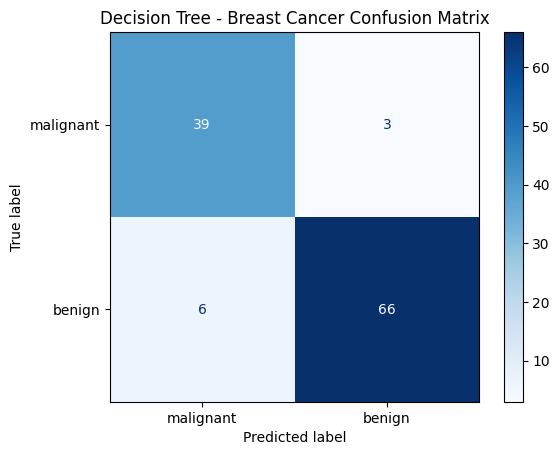

In [26]:
cm_cancer = confusion_matrix(yc_test, yc_pred)

print("Confusion Matrix:")
print(cm_cancer)

ConfusionMatrixDisplay(
    confusion_matrix=cm_cancer,
    display_labels=cancer.target_names
).plot(cmap="Blues", values_format="d")

plt.title("Decision Tree - Breast Cancer Confusion Matrix")
plt.show()

In [27]:
# Load dataset
wine = load_wine()

# Create DataFrame
wine_df = pd.DataFrame(
    wine.data,
    columns=wine.feature_names
)

wine_df["target"] = wine.target

print("First five rows:")
display(wine_df.head())

print("\nDataset shape:", wine_df.shape)

print("\nWine classes:")
print(dict(enumerate(wine.target_names)))

print("\nClass distribution:")
print(wine_df["target"].value_counts().sort_index())

First five rows:


,alcohol,malic_acid,ash,alcalinity_of_ash,magnesium,total_phenols,flavanoids,nonflavanoid_phenols,proanthocyanins,color_intensity,hue,od280/od315_of_diluted_wines,proline,target
0,14.23,1.71,2.43,15.6,127.0,2.80,3.06,0.28,2.29,5.64,1.04,3.92,1065.0,0
1,13.20,1.78,2.14,11.2,100.0,2.65,2.76,0.26,1.28,4.38,1.05,3.40,1050.0,0
2,13.16,2.36,2.67,18.6,101.0,2.80,3.24,0.30,2.81,5.68,1.03,3.17,1185.0,0
3,14.37,1.95,2.50,16.8,113.0,3.85,3.49,0.24,2.18,7.80,0.86,3.45,1480.0,0
4,13.24,2.59,2.87,21.0,118.0,2.80,2.69,0.39,1.82,4.32,1.04,2.93,735.0,0



Dataset shape: (178, 14)

Wine classes:
{0: np.str_('class_0'), 1: np.str_('class_1'), 2: np.str_('class_2')}

Class distribution:
target
0    59
1    71
2    48
Name: count, dtype: int64


In [28]:
print("Dataset information:")
wine_df.info()

print("\nStatistical summary:")
display(wine_df.describe())

print("\nMissing values:", wine_df.isnull().sum().sum())

print("Duplicate rows:", wine_df.duplicated().sum())

Dataset information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 178 entries, 0 to 177
Data columns (total 14 columns):
 #   Column                        Non-Null Count  Dtype  
---  ------                        --------------  -----  
 0   alcohol                       178 non-null    float64
 1   malic_acid                    178 non-null    float64
 2   ash                           178 non-null    float64
 3   alcalinity_of_ash             178 non-null    float64
 4   magnesium                     178 non-null    float64
 5   total_phenols                 178 non-null    float64
 6   flavanoids                    178 non-null    float64
 7   nonflavanoid_phenols          178 non-null    float64
 8   proanthocyanins               178 non-null    float64
 9   color_intensity               178 non-null    float64
 10  hue                           178 non-null    float64
 11  od280/od315_of_diluted_wines  178 non-null    float64
 12  proline                       178 non-null 

,alcohol,malic_acid,ash,alcalinity_of_ash,magnesium,total_phenols,flavanoids,nonflavanoid_phenols,proanthocyanins,color_intensity,hue,od280/od315_of_diluted_wines,proline,target
count,178.000000,178.000000,178.000000,178.000000,178.000000,178.000000,178.000000,178.000000,178.000000,178.000000,178.000000,178.000000,178.000000,178.000000
mean,13.000618,2.336348,2.366517,19.494944,99.741573,2.295112,2.029270,0.361854,1.590899,5.058090,0.957449,2.611685,746.893258,0.938202
std,0.811827,1.117146,0.274344,3.339564,14.282484,0.625851,0.998859,0.124453,0.572359,2.318286,0.228572,0.709990,314.907474,0.775035
min,11.030000,0.740000,1.360000,10.600000,70.000000,0.980000,0.340000,0.130000,0.410000,1.280000,0.480000,1.270000,278.000000,0.000000
25%,12.362500,1.602500,2.210000,17.200000,88.000000,1.742500,1.205000,0.270000,1.250000,3.220000,0.782500,1.937500,500.500000,0.000000
50%,13.050000,1.865000,2.360000,19.500000,98.000000,2.355000,2.135000,0.340000,1.555000,4.690000,0.965000,2.780000,673.500000,1.000000
75%,13.677500,3.082500,2.557500,21.500000,107.000000,2.800000,2.875000,0.437500,1.950000,6.200000,1.120000,3.170000,985.000000,2.000000
max,14.830000,5.800000,3.230000,30.000000,162.000000,3.880000,5.080000,0.660000,3.580000,13.000000,1.710000,4.000000,1680.000000,2.000000



Missing values: 0
Duplicate rows: 0


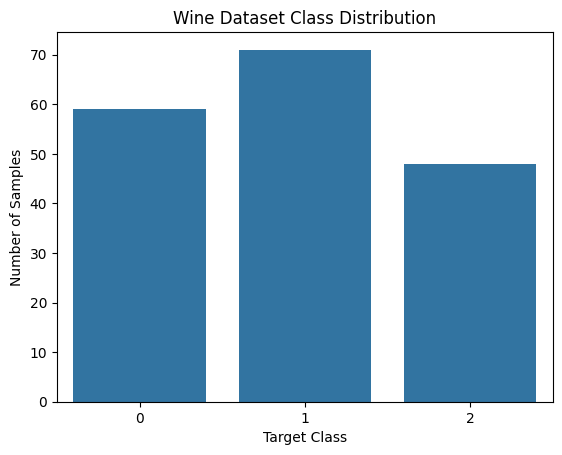

In [29]:
sns.countplot(x=wine_df["target"])

plt.title("Wine Dataset Class Distribution")
plt.xlabel("Target Class")
plt.ylabel("Number of Samples")
plt.show()

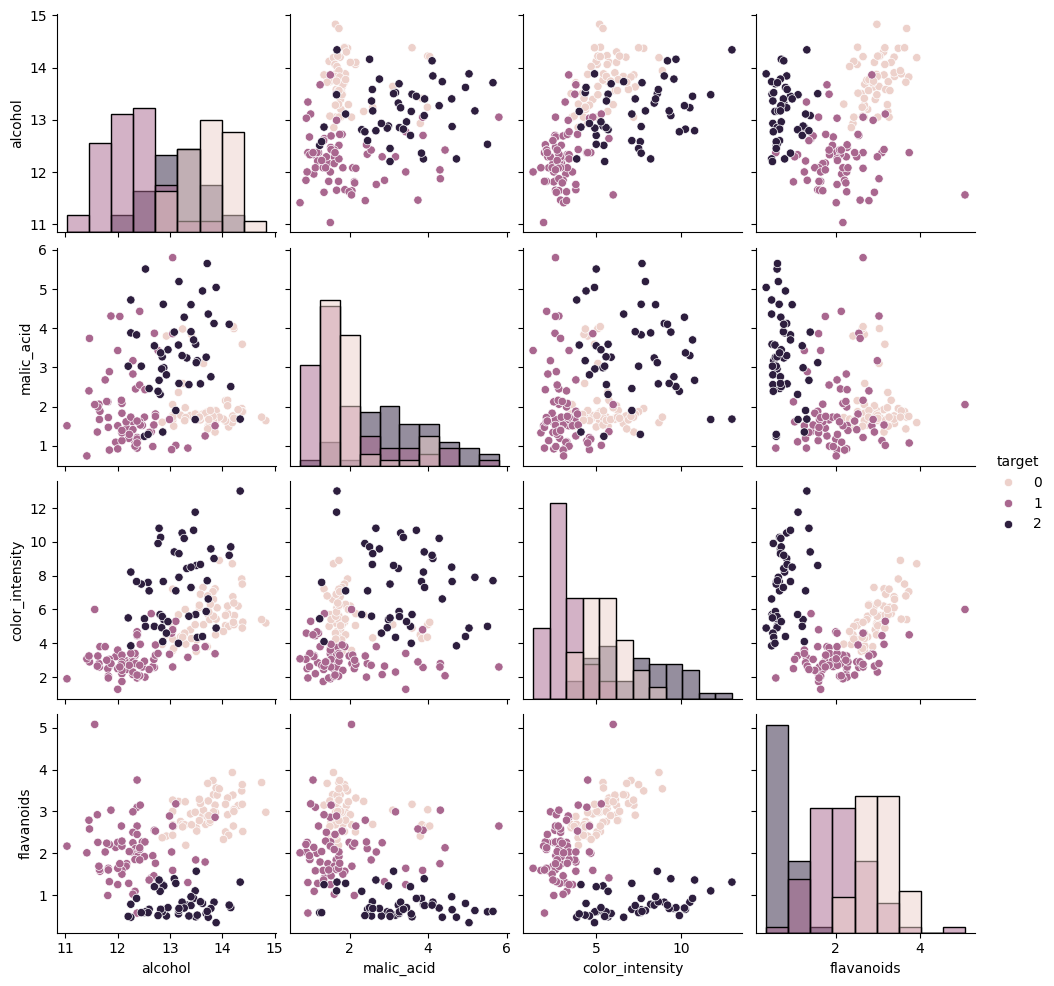

In [30]:
selected_features = [
    "alcohol",
    "malic_acid",
    "color_intensity",
    "flavanoids"
]

sns.pairplot(
    wine_df[selected_features + ["target"]],
    hue="target",
    diag_kind="hist"
)

plt.show()

In [31]:
X_wine = wine.data
y_wine = wine.target

print("Number of input features:", X_wine.shape[1])
print("Number of samples:", X_wine.shape[0])

Xw_train, Xw_test, yw_train, yw_test = train_test_split(
    X_wine,
    y_wine,
    test_size=0.20,
    random_state=42,
    stratify=y_wine
)

print("\nTraining samples:", len(Xw_train))
print("Testing samples:", len(Xw_test))

Number of input features: 13
Number of samples: 178

Training samples: 142
Testing samples: 36


In [32]:
# Create Random Forest model
rf_model = RandomForestClassifier(
    n_estimators=100,
    random_state=42
)

# Train the model
rf_model.fit(Xw_train, yw_train)

# Generate predictions
yw_pred = rf_model.predict(Xw_test)

print("Random Forest trained successfully!")
print("\nFirst 10 actual labels:", yw_test[:10])
print("First 10 predicted labels:", yw_pred[:10])

Random Forest trained successfully!

First 10 actual labels: [0 2 0 1 1 0 0 1 1 2]
First 10 predicted labels: [0 2 0 1 1 0 0 1 1 2]


In [33]:
wine_accuracy = accuracy_score(yw_test, yw_pred)

wine_precision = precision_score(
    yw_test, yw_pred, average="macro", zero_division=0
)

wine_recall = recall_score(
    yw_test, yw_pred, average="macro", zero_division=0
)

wine_f1 = f1_score(
    yw_test, yw_pred, average="macro", zero_division=0
)

print(f"Accuracy:  {wine_accuracy:.4f}")
print(f"Precision: {wine_precision:.4f}")
print(f"Recall:    {wine_recall:.4f}")
print(f"F1-score:  {wine_f1:.4f}")

print("\nClassification Report:")
print(
    classification_report(
        yw_test,
        yw_pred,
        target_names=wine.target_names,
        zero_division=0
    )
)

Accuracy:  1.0000
Precision: 1.0000
Recall:    1.0000
F1-score:  1.0000

Classification Report:
              precision    recall  f1-score   support

     class_0       1.00      1.00      1.00        12
     class_1       1.00      1.00      1.00        14
     class_2       1.00      1.00      1.00        10

    accuracy                           1.00        36
   macro avg       1.00      1.00      1.00        36
weighted avg       1.00      1.00      1.00        36



Confusion Matrix:
[[12  0  0]
 [ 0 14  0]
 [ 0  0 10]]


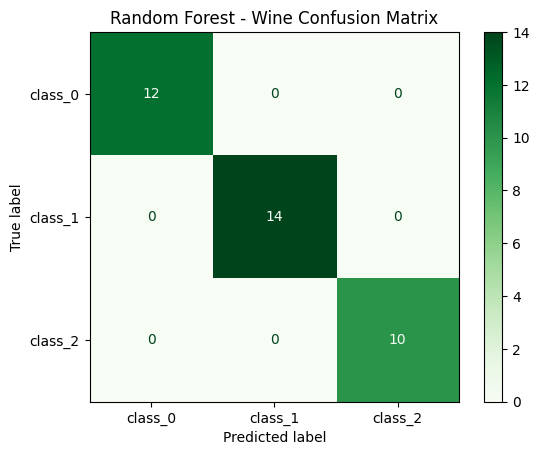

In [34]:
cm_wine = confusion_matrix(yw_test, yw_pred)

print("Confusion Matrix:")
print(cm_wine)

ConfusionMatrixDisplay(
    confusion_matrix=cm_wine,
    display_labels=wine.target_names
).plot(cmap="Greens", values_format="d")

plt.title("Random Forest - Wine Confusion Matrix")
plt.show()

In [35]:
# Load dataset
diabetes = load_diabetes()

# Create DataFrame
diabetes_df = pd.DataFrame(
    diabetes.data,
    columns=diabetes.feature_names
)

diabetes_df["target"] = diabetes.target

print("First five rows:")
display(diabetes_df.head())

print("\nDataset shape:", diabetes_df.shape)

print("\nInput features:")
print(diabetes.feature_names)

print("\nTarget description:")
print(diabetes.DESCR.split("Attribute Information:")[0])

First five rows:


,age,sex,bmi,bp,s1,s2,s3,s4,s5,s6,target
0,0.038076,0.050680,0.061696,0.021872,-0.044223,-0.034821,-0.043401,-0.002592,0.019907,-0.017646,151.0
1,-0.001882,-0.044642,-0.051474,-0.026328,-0.008449,-0.019163,0.074412,-0.039493,-0.068332,-0.092204,75.0
2,0.085299,0.050680,0.044451,-0.005670,-0.045599,-0.034194,-0.032356,-0.002592,0.002861,-0.025930,141.0
3,-0.089063,-0.044642,-0.011595,-0.036656,0.012191,0.024991,-0.036038,0.034309,0.022688,-0.009362,206.0
4,0.005383,-0.044642,-0.036385,0.021872,0.003935,0.015596,0.008142,-0.002592,-0.031988,-0.046641,135.0



Dataset shape: (442, 11)

Input features:
['age', 'sex', 'bmi', 'bp', 's1', 's2', 's3', 's4', 's5', 's6']

Target description:
.. _diabetes_dataset:

Diabetes dataset
----------------

Ten baseline variables, age, sex, body mass index, average blood
pressure, and six blood serum measurements were obtained for each of n =
442 diabetes patients, as well as the response of interest, a
quantitative measure of disease progression one year after baseline.

**Data Set Characteristics:**

:Number of Instances: 442

:Number of Attributes: First 10 columns are numeric predictive values

:Target: Column 11 is a quantitative measure of disease progression one year after baseline

:


In [36]:
print("Dataset information:")
diabetes_df.info()

print("\nStatistical summary:")
display(diabetes_df.describe())

print("\nMissing values:", diabetes_df.isnull().sum().sum())

print("Duplicate rows:", diabetes_df.duplicated().sum())

Dataset information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 442 entries, 0 to 441
Data columns (total 11 columns):
 #   Column  Non-Null Count  Dtype  
---  ------  --------------  -----  
 0   age     442 non-null    float64
 1   sex     442 non-null    float64
 2   bmi     442 non-null    float64
 3   bp      442 non-null    float64
 4   s1      442 non-null    float64
 5   s2      442 non-null    float64
 6   s3      442 non-null    float64
 7   s4      442 non-null    float64
 8   s5      442 non-null    float64
 9   s6      442 non-null    float64
 10  target  442 non-null    float64
dtypes: float64(11)
memory usage: 38.1 KB

Statistical summary:


,age,sex,bmi,bp,s1,s2,s3,s4,s5,s6,target
count,4.420000e+02,4.420000e+02,4.420000e+02,4.420000e+02,4.420000e+02,4.420000e+02,4.420000e+02,4.420000e+02,4.420000e+02,4.420000e+02,442.000000
mean,-2.511817e-19,1.230790e-17,-2.245564e-16,-4.797570e-17,-1.381499e-17,3.918434e-17,-5.777179e-18,-9.042540e-18,9.293722e-17,1.130318e-17,152.133484
std,4.761905e-02,4.761905e-02,4.761905e-02,4.761905e-02,4.761905e-02,4.761905e-02,4.761905e-02,4.761905e-02,4.761905e-02,4.761905e-02,77.093005
min,-1.072256e-01,-4.464164e-02,-9.027530e-02,-1.123988e-01,-1.267807e-01,-1.156131e-01,-1.023071e-01,-7.639450e-02,-1.260971e-01,-1.377672e-01,25.000000
25%,-3.729927e-02,-4.464164e-02,-3.422907e-02,-3.665608e-02,-3.424784e-02,-3.035840e-02,-3.511716e-02,-3.949338e-02,-3.324559e-02,-3.317903e-02,87.000000
50%,5.383060e-03,-4.464164e-02,-7.283766e-03,-5.670422e-03,-4.320866e-03,-3.819065e-03,-6.584468e-03,-2.592262e-03,-1.947171e-03,-1.077698e-03,140.500000
75%,3.807591e-02,5.068012e-02,3.124802e-02,3.564379e-02,2.835801e-02,2.984439e-02,2.931150e-02,3.430886e-02,3.243232e-02,2.791705e-02,211.500000
max,1.107267e-01,5.068012e-02,1.705552e-01,1.320436e-01,1.539137e-01,1.987880e-01,1.811791e-01,1.852344e-01,1.335973e-01,1.356118e-01,346.000000



Missing values: 0
Duplicate rows: 0


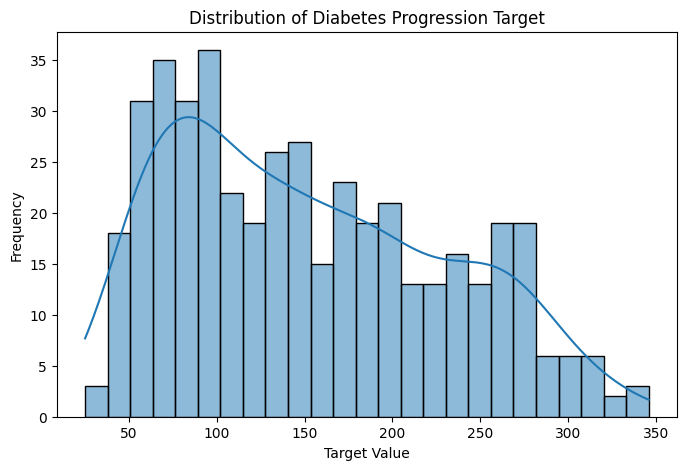

In [37]:
plt.figure(figsize=(8, 5))

sns.histplot(
    diabetes_df["target"],
    bins=25,
    kde=True
)

plt.title("Distribution of Diabetes Progression Target")
plt.xlabel("Target Value")
plt.ylabel("Frequency")
plt.show()

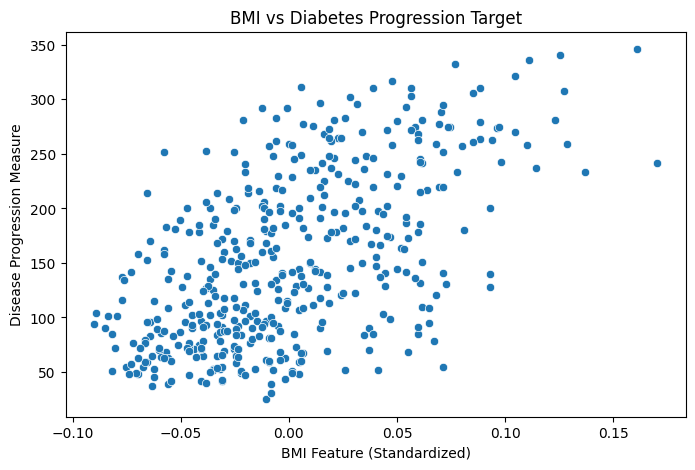

In [38]:
plt.figure(figsize=(8, 5))

sns.scatterplot(
    data=diabetes_df,
    x="bmi",
    y="target"
)

plt.title("BMI vs Diabetes Progression Target")
plt.xlabel("BMI Feature (Standardized)")
plt.ylabel("Disease Progression Measure")
plt.show()

In [39]:
X_diabetes = diabetes.data
y_diabetes = diabetes.target

print("Number of input features:", X_diabetes.shape[1])
print("Number of samples:", X_diabetes.shape[0])

Xd_train, Xd_test, yd_train, yd_test = train_test_split(
    X_diabetes,
    y_diabetes,
    test_size=0.20,
    random_state=42
)

print("\nTraining samples:", len(Xd_train))
print("Testing samples:", len(Xd_test))

Number of input features: 10
Number of samples: 442

Training samples: 353
Testing samples: 89


In [40]:
# Create Gradient Boosting regression model
gb_model = GradientBoostingRegressor(
    n_estimators=100,
    learning_rate=0.05,
    max_depth=2,
    random_state=42
)

# Train the model
gb_model.fit(Xd_train, yd_train)

# Generate predictions
yd_pred = gb_model.predict(Xd_test)

print("Gradient Boosting regressor trained successfully!")

print("\nFirst 10 actual target values:")
print(yd_test[:10])

print("\nFirst 10 predicted target values:")
print(np.round(yd_pred[:10], 2))

Gradient Boosting regressor trained successfully!

First 10 actual target values:
[219.  70. 202. 230. 111.  84. 242. 272.  94.  96.]

First 10 predicted target values:
[162.   178.9  171.6  264.02 116.27 109.57 240.58 201.02 148.79 149.6 ]


In [41]:
# Calculate regression metrics
diabetes_mae = mean_absolute_error(yd_test, yd_pred)
diabetes_mse = mean_squared_error(yd_test, yd_pred)
diabetes_rmse = np.sqrt(diabetes_mse)
diabetes_r2 = r2_score(yd_test, yd_pred)

print(f"MAE:  {diabetes_mae:.4f}")
print(f"MSE:  {diabetes_mse:.4f}")
print(f"RMSE: {diabetes_rmse:.4f}")
print(f"R² Score: {diabetes_r2:.4f}")

MAE:  42.5461
MSE:  2742.8830
RMSE: 52.3725
R² Score: 0.4823


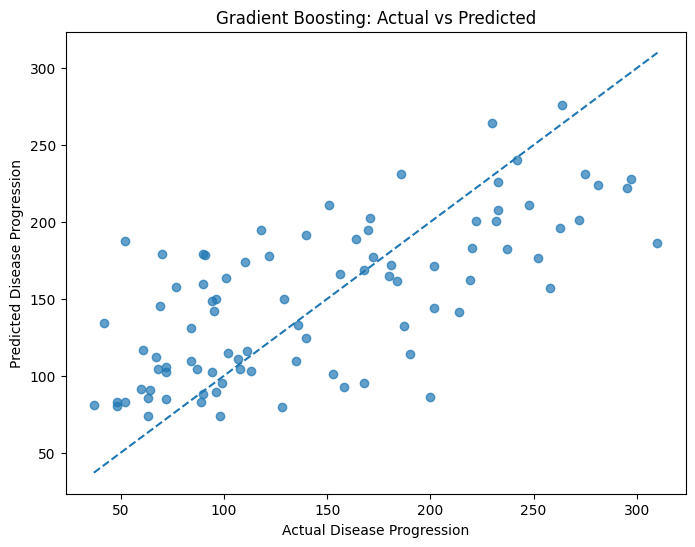

In [42]:
plt.figure(figsize=(8, 6))

plt.scatter(yd_test, yd_pred, alpha=0.7)

# Reference line for perfect predictions
min_value = min(yd_test.min(), yd_pred.min())
max_value = max(yd_test.max(), yd_pred.max())

plt.plot(
    [min_value, max_value],
    [min_value, max_value],
    linestyle="--"
)

plt.xlabel("Actual Disease Progression")
plt.ylabel("Predicted Disease Progression")
plt.title("Gradient Boosting: Actual vs Predicted")
plt.show()

In [43]:
# Classification comparison
classification_results = pd.DataFrame({
    "Model": [
        "Decision Tree - Breast Cancer",
        "Random Forest - Wine"
    ],
    "Accuracy": [
        cancer_accuracy,
        wine_accuracy
    ],
    "Macro Precision": [
        cancer_precision,
        wine_precision
    ],
    "Macro Recall": [
        cancer_recall,
        wine_recall
    ],
    "Macro F1-score": [
        cancer_f1,
        wine_f1
    ]
})

print("CLASSIFICATION MODEL COMPARISON")
display(classification_results.round(4))

# Regression results
regression_results = pd.DataFrame({
    "Model": ["Gradient Boosting - Diabetes"],
    "MAE": [diabetes_mae],
    "MSE": [diabetes_mse],
    "RMSE": [diabetes_rmse],
    "R2 Score": [diabetes_r2]
})

print("REGRESSION MODEL RESULTS")
display(regression_results.round(4))

CLASSIFICATION MODEL COMPARISON


,Model,Accuracy,Macro Precision,Macro Recall,Macro F1-score
0,Decision Tree - Breast Cancer,0.9211,0.9116,0.9226,0.9164
1,Random Forest - Wine,1.0000,1.0000,1.0000,1.0000


REGRESSION MODEL RESULTS


,Model,MAE,MSE,RMSE,R2 Score
0,Gradient Boosting - Diabetes,42.5461,2742.883,52.3725,0.4823


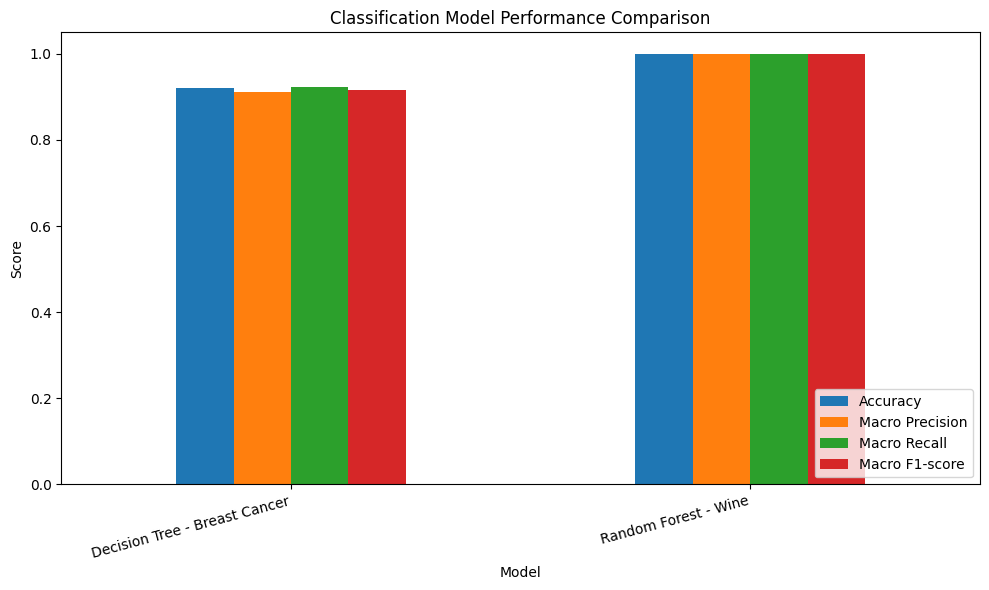

In [44]:
classification_results.set_index("Model")[
    ["Accuracy", "Macro Precision", "Macro Recall", "Macro F1-score"]
].plot(kind="bar", figsize=(10, 6), ylim=(0, 1.05))

plt.title("Classification Model Performance Comparison")
plt.ylabel("Score")
plt.xticks(rotation=15, ha="right")
plt.legend(loc="lower right")
plt.tight_layout()
plt.show()